# Job Search Funnel Analysis

**Business question:** Where in my job search do applications get lost, which
channels lead to interviews, and how long should I wait before following up?

**Data:** two CSV files exported from the JobTrack app (Analytics page →
*Export CSV*). See [`docs/data-dictionary.md`](../docs/data-dictionary.md) for
every column and [`docs/metrics.md`](../docs/metrics.md) for every metric.

**How to use this notebook**

1. Export both CSV files from the app and put them in `analysis/data/raw/`.
2. Run all cells (*Run All*). The notebook uses the newest files in `data/raw/`.
3. If `data/raw/` is empty it falls back to **synthetic practice data**. Results
   from synthetic data are *made up*: use them to learn the steps, never as findings.

**What this notebook covers**

| Step | Skill it demonstrates |
|---|---|
| 1–2 Load and first look | Reading data, data types |
| 3 Data quality checks | Profiling, finding problems before trusting numbers |
| 4 Cleaning | Standardising messy text, removing duplicates, documenting decisions |
| 5 Feature engineering | Turning raw events into one row per application |
| 6 KPIs | Metric definitions, checking results against the app |
| 7–10 Funnel, trend, channels, response time | Exploratory analysis, uncertainty, hypothesis testing |
| 11 SQL | The same KPIs in SQL: `JOIN`, `GROUP BY`, CTEs, window functions |
| 12 Summary | Saving results for the write-up |

In [1]:
from pathlib import Path
import json
import math
import re

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

STATUSES = ["Applied", "Interview", "Offer", "Rejected"]
STALE_AFTER_DAYS = 21   # same rule as the app: no reply after 21 days = stale

# Same chart colours as the app's Analytics page
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9ca3af"
FUNNEL_COLORS = ["#86b6ef", "#5598e7", "#256abf", "#184f95"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e7eb",
    "axes.axisbelow": True,
    "font.size": 10,
})

OUTPUT_DIR = Path("outputs")
(OUTPUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

## 1. Load the data

The notebook picks the **newest real export** in `data/raw/` if there is one,
and otherwise the synthetic practice files. It prints which one it used, so the
results are never confused.

We read every column as text first (`dtype=str`) and convert types ourselves.
That way nothing is silently guessed: for example a `job_id` that happens to
look like a number stays text, and only truly empty cells count as missing.

In [2]:
DATA_DIR = Path("data")

def newest(folder, pattern):
    files = sorted(folder.glob(pattern))   # file names end in YYYY-MM-DD, so the last is newest
    return files[-1] if files else None

real_apps = newest(DATA_DIR / "raw", "jobtrack_applications_*.csv")
real_events = newest(DATA_DIR / "raw", "jobtrack_status_events_*.csv")

if real_apps and real_events:
    APPS_FILE, EVENTS_FILE, IS_SYNTHETIC = real_apps, real_events, False
else:
    APPS_FILE = DATA_DIR / "synthetic" / "jobtrack_applications_SYNTHETIC.csv"
    EVENTS_FILE = DATA_DIR / "synthetic" / "jobtrack_status_events_SYNTHETIC.csv"
    IS_SYNTHETIC = True

print("=" * 72)
print("DATA SOURCE:", "SYNTHETIC practice data (made up, NOT real results)" if IS_SYNTHETIC
      else "REAL export from JobTrack")
print("  applications: ", APPS_FILE)
print("  status events:", EVENTS_FILE)
print("=" * 72)

DATA SOURCE: SYNTHETIC practice data (made up, NOT real results)
  applications:  data\synthetic\jobtrack_applications_SYNTHETIC.csv
  status events: data\synthetic\jobtrack_status_events_SYNTHETIC.csv


In [3]:
# Only empty cells are missing values (a company literally called "NA" stays "NA")
read_options = dict(dtype=str, keep_default_na=False, na_values=[""])

raw_apps = pd.read_csv(APPS_FILE, **read_options)
raw_events = pd.read_csv(EVENTS_FILE, **read_options)

def parse_types(apps, events):
    """Convert text columns to proper types. All times are in UTC."""
    apps = apps.copy()
    events = events.copy()
    apps["date_applied"] = pd.to_datetime(apps["date_applied"], format="%Y-%m-%d", utc=True)
    apps["created_at"] = pd.to_datetime(apps["created_at"], utc=True)
    apps["updated_at"] = pd.to_datetime(apps["updated_at"], utc=True)
    events["event_number"] = events["event_number"].astype(int)
    events["changed_at"] = pd.to_datetime(events["changed_at"], utc=True)
    return apps, events

raw_apps, raw_events = parse_types(raw_apps, raw_events)

# "Today" for this analysis = the latest moment recorded in the export.
# Using the data's own date (not the computer's clock) makes results reproducible.
AS_OF = max(raw_apps["updated_at"].max(), raw_events["changed_at"].max())
print("Analysis as of:", AS_OF.strftime("%Y-%m-%d %H:%M UTC"))

Analysis as of: 2026-11-03 15:03 UTC


## 2. First look

Before calculating anything: how big is the data, what does a row look like,
and what values appear in each category?

In [4]:
print(f"applications:  {raw_apps.shape[0]} rows x {raw_apps.shape[1]} columns")
print(f"status events: {raw_events.shape[0]} rows x {raw_events.shape[1]} columns")
print(f"date range:    {raw_apps['date_applied'].min():%d %b %Y} to {raw_apps['date_applied'].max():%d %b %Y}")
raw_apps.head()

applications:  62 rows x 9 columns
status events: 102 rows x 4 columns
date range:    25 Aug 2026 to 28 Oct 2026


,job_id,company,role,location,source,current_status,date_applied,created_at,updated_at
0,bd4755d05ad7853c1f76eb97,Lumen Education,Junior Data Analyst,Pune,Company Website,Rejected,2026-08-25 00:00:00+00:00,2026-08-25 17:36:00+00:00,2026-09-11 04:27:00+00:00
1,ff6c15c0c8e9df469611a11f,Fernway Pharma,Data Analyst,Pune,LinkedIn,Applied,2026-08-25 00:00:00+00:00,2026-08-25 13:56:00+00:00,2026-08-25 13:56:00+00:00
2,5fe85df2fbdaa35adf9c1e2a,Brightwater Studios,Business Analyst,Remote,LinkedIn,Applied,2026-08-26 00:00:00+00:00,2026-08-26 16:32:00+00:00,2026-08-26 16:32:00+00:00
3,7a9ceb98bfe3fa6bad17408d,Brightwater Studios,Business Analyst,Remote,LinkedIn,Applied,2026-08-26 00:00:00+00:00,2026-08-26 16:35:00+00:00,2026-08-26 16:35:00+00:00
4,dc77eb48631d076231e171ce,Ember Robotics,Junior Data Analyst,Mumbai,Recruiter,Applied,2026-08-26 00:00:00+00:00,2026-08-27 18:16:00+00:00,2026-08-27 18:16:00+00:00


In [5]:
raw_apps.dtypes

job_id                            str
company                           str
role                              str
location                          str
source                            str
current_status                    str
date_applied      datetime64[us, UTC]
created_at        datetime64[us, UTC]
updated_at        datetime64[us, UTC]
dtype: object

In [6]:
# value_counts(dropna=False) also counts missing values, which are easy to forget
for column in ["current_status", "source", "location"]:
    print(raw_apps[column].value_counts(dropna=False).to_string(), "\n")

current_status
Applied     36
Rejected    23
Offer        3 

source
LinkedIn           21
NaN                14
Company Website    10
Referral           10
Job Board           4
Recruiter           3 

location
Remote       12
Bangalore    12
Pune         10
Bengaluru     9
NaN           8
Hyderabad     6
Mumbai        5 



## 3. Data quality checks

Numbers are only as good as the data behind them. Manually entered data is
messy, so we **check before we trust**. Each check says how many rows are
affected and why it matters.

The helper functions below standardise text so we can spot variants of the same
value (for example `"Northwind Analytics Inc."` and `"northwind analytics"`).

In [7]:
# Words that don't change which company it is
COMPANY_SUFFIXES = r"\b(inc|ltd|pvt|private|limited|llc|llp|corp|corporation|co)\b"
CITY_ALIASES = {"bangalore": "bengaluru", "bombay": "mumbai", "gurgaon": "gurugram",
                "madras": "chennai", "calcutta": "kolkata", "work from home": "remote", "wfh": "remote"}

def tidy_text(series):
    """Trim and collapse spaces; undo the export's spreadsheet-safety apostrophe."""
    series = series.str.strip().str.replace(r"\s+", " ", regex=True)
    return series.str.replace(r"^'(?=[=+\-@])", "", regex=True)

def company_key(series):
    key = tidy_text(series).str.casefold().str.replace(r"[.,]", " ", regex=True)
    key = key.str.replace(COMPANY_SUFFIXES, " ", regex=True)
    return key.str.replace(r"\s+", " ", regex=True).str.strip()

def simple_key(series):
    return tidy_text(series).str.casefold()

def location_key(series):
    return simple_key(series).replace(CITY_ALIASES)

In [8]:
def days_to_first_response(apps, events):
    """Whole UTC days from applying to the first non-Applied event (same as the app)."""
    first = events[events["status"] != "Applied"].groupby("job_id")["changed_at"].min()
    applied = apps.set_index("job_id")["date_applied"]
    return (first.dt.floor("D") - applied.reindex(first.index)).dt.days

def quality_report(apps, events, as_of):
    days = days_to_first_response(apps, events)
    last_event = events.sort_values("event_number").groupby("job_id")["status"].last()
    current = apps.set_index("job_id")["current_status"]
    duplicate_keys = ["company_key", "role_key", "date_applied"]
    keyed = apps.assign(company_key=company_key(apps["company"]), role_key=simple_key(apps["role"]))

    def variants(raw, key):
        spellings = pd.DataFrame({"raw": tidy_text(raw), "key": key}).dropna()
        counts = spellings.groupby("key")["raw"].nunique()
        return int((counts > 1).sum())

    checks = [
        ("Missing source", apps["source"].isna().sum(), "can't compare channels for these rows"),
        ("Missing location", apps["location"].isna().sum(), "limits location analysis"),
        ("Duplicate job_id", apps["job_id"].duplicated().sum(), "the ID must be unique"),
        ("Likely duplicate applications (same company, role, date)",
         keyed.duplicated(duplicate_keys).sum(), "double-counting inflates the totals"),
        ("Companies spelled more than one way", variants(apps["company"], company_key(apps["company"])),
         "splits one company into several"),
        ("Locations spelled more than one way", variants(apps["location"], location_key(apps["location"])),
         "splits one city into several"),
        ("Roles spelled more than one way", variants(apps["role"], simple_key(apps["role"])),
         "splits one role into several"),
        ("Events for an unknown job_id", (~events["job_id"].isin(apps["job_id"])).sum(),
         "broken link between the two files"),
        ("Applications with no events", (~apps["job_id"].isin(events["job_id"])).sum(),
         "stage dates unknown (created before history tracking)"),
        ("Current status differs from last event", (last_event.reindex(current.index) != current)
         [current.index.isin(last_event.index)].sum(), "the two files disagree"),
        ("Reply same day but -1 day in UTC", (days == -1).sum(), "timezone effect; treated as 0 days"),
        ("Reply dated before applying (< -1 day)", (days < -1).sum(), "impossible; excluded from response time"),
        ("Applied after the export date", (apps["date_applied"] > as_of).sum(), "impossible date"),
    ]
    report = pd.DataFrame(checks, columns=["check", "rows", "why it matters"])
    report["rows"] = report["rows"].astype(int)
    report.insert(0, "status", report["rows"].map(lambda n: "OK" if n == 0 else "ISSUE"))
    return report

quality_report(raw_apps, raw_events, AS_OF)

,status,check,rows,why it matters
0,ISSUE,Missing source,14,can't compare channels for these rows
1,ISSUE,Missing location,8,limits location analysis
2,OK,Duplicate job_id,0,the ID must be unique
3,ISSUE,"Likely duplicate applications (same company, r...",2,double-counting inflates the totals
4,ISSUE,Companies spelled more than one way,2,splits one company into several
5,ISSUE,Locations spelled more than one way,1,splits one city into several
6,ISSUE,Roles spelled more than one way,1,splits one role into several
7,OK,Events for an unknown job_id,0,broken link between the two files
8,OK,Applications with no events,0,stage dates unknown (created before history tr...
9,OK,Current status differs from last event,0,the two files disagree


In [9]:
# Look at the actual variants, not just the counts
spellings = pd.DataFrame({"spelling": tidy_text(raw_apps["company"]), "key": company_key(raw_apps["company"])})
variant_keys = spellings.groupby("key")["spelling"].nunique().loc[lambda n: n > 1].index
(spellings[spellings["key"].isin(variant_keys)]
 .groupby("key")["spelling"].unique().to_frame("spellings found"))

,spellings found
key,
northwind analytics,"[Northwind Analytics, northwind analytics, Nor..."
quantia labs,"[QUANTIA LABS, Quantia Labs, Quantia Labs Pvt ..."


## 4. Cleaning

Cleaning rules, decided **before** looking at results so they can't be bent to
produce a nicer number:

| Problem | Decision | Why |
|---|---|---|
| Extra spaces, export apostrophe | Trim; remove the safety apostrophe | Formatting, not meaning |
| Same company / role / city spelled differently | Group by a standardised key; show the most common spelling | One real-world thing = one value |
| Same company, role and date entered twice | Keep the first entry, drop the copy and its events | Counting it twice inflates every total |
| Missing source | Label as `Unknown` (kept, not dropped) | Dropping rows would bias the rates |
| Reply dated before applying | Keep the row, exclude it from response-time stats only | One bad date shouldn't remove the whole application |

The raw data is never modified: cleaning produces new tables, and every step is
logged with the number of rows it changed.

In [10]:
def most_common_spelling(raw, key):
    """For each key, the spelling used most often (ties: alphabetical)."""
    pairs = pd.DataFrame({"raw": raw, "key": key}).dropna()
    counts = pairs.value_counts(["key", "raw"]).reset_index(name="n")
    best = counts.sort_values(["key", "n", "raw"], ascending=[True, False, True]).drop_duplicates("key")
    return key.map(best.set_index("key")["raw"])

def count_changed(before, after):
    """Rows whose value changed. Two missing values count as unchanged
    (in pandas, missing != missing is True, which would over-count)."""
    same = before.eq(after) | (before.isna() & after.isna())
    return int((~same).sum())

def clean(apps, events):
    log = []
    apps = apps.copy()

    for column in ["company", "role", "location"]:
        before = apps[column].copy()
        apps[column] = tidy_text(apps[column])
        log.append((f"Trim spaces / apostrophe in {column}", count_changed(before, apps[column])))

    for column, key_function in [("company", company_key), ("role", simple_key), ("location", location_key)]:
        before = apps[column].copy()
        apps[f"{column}_key"] = key_function(apps[column])
        apps[column] = most_common_spelling(apps[column], apps[f"{column}_key"])
        log.append((f"Standardise {column} spellings", count_changed(before, apps[column])))

    missing_source = apps["source"].isna()
    apps["source"] = apps["source"].fillna("Unknown")
    log.append(("Missing source -> 'Unknown'", int(missing_source.sum())))

    duplicate = apps.sort_values("created_at").duplicated(["company_key", "role_key", "date_applied"])
    duplicate_ids = apps.loc[duplicate.reindex(apps.index), "job_id"]
    apps = apps[~apps["job_id"].isin(duplicate_ids)]
    events = events[~events["job_id"].isin(duplicate_ids)]
    log.append(("Remove duplicate applications (and their events)", len(duplicate_ids)))

    apps = apps.drop(columns=["company_key", "role_key", "location_key"]).reset_index(drop=True)
    return apps, events.reset_index(drop=True), pd.DataFrame(log, columns=["cleaning step", "rows changed"])

clean_apps, clean_events, cleaning_log = clean(raw_apps, raw_events)
print(f"applications: {len(raw_apps)} raw -> {len(clean_apps)} clean")
cleaning_log

applications: 62 raw -> 60 clean


,cleaning step,rows changed
0,Trim spaces / apostrophe in company,1
1,Trim spaces / apostrophe in role,0
2,Trim spaces / apostrophe in location,0
3,Standardise company spellings,5
4,Standardise role spellings,19
5,Standardise location spellings,9
6,Missing source -> 'Unknown',14
7,Remove duplicate applications (and their events),2


In [11]:
# Re-run the quality checks on the cleaned data: the fixable issues should now be 0
quality_report(clean_apps, clean_events, AS_OF)

,status,check,rows,why it matters
0,OK,Missing source,0,can't compare channels for these rows
1,ISSUE,Missing location,8,limits location analysis
2,OK,Duplicate job_id,0,the ID must be unique
3,OK,"Likely duplicate applications (same company, r...",0,double-counting inflates the totals
4,OK,Companies spelled more than one way,0,splits one company into several
5,OK,Locations spelled more than one way,0,splits one city into several
6,OK,Roles spelled more than one way,0,splits one role into several
7,OK,Events for an unknown job_id,0,broken link between the two files
8,OK,Applications with no events,0,stage dates unknown (created before history tr...
9,OK,Current status differs from last event,0,the two files disagree


## 5. Feature engineering: one row per application

The status history has several rows per application. To analyse the funnel we
need **one row per application** with yes/no flags. This is the most important
step: it is where the metric definitions from `docs/metrics.md` become code.

- `responded`: ever moved past *Applied* (a rejection counts as a reply)
- `reached_interview`: ever at *Interview* or *Offer* (an offer implies an interview)
- `reached_offer`: ever at *Offer*
- `days_to_response`: days from applying to the first reply
- `mature`: applied at least 21 days ago, so it has had a fair chance to get a reply

In [12]:
def build_features(apps, events, as_of):
    features = apps.set_index("job_id").copy()

    # One column per status: True if the application ever had that status
    had = pd.crosstab(events["job_id"], events["status"]).gt(0)
    had = had.reindex(index=features.index, columns=STATUSES, fill_value=False)

    def ever(status):
        # the history, or the current status for records without history
        return had[status] | (features["current_status"] == status)

    features["responded"] = ever("Interview") | ever("Offer") | ever("Rejected")
    features["reached_interview"] = ever("Interview") | ever("Offer")
    features["reached_offer"] = ever("Offer")
    features["rejected"] = features["current_status"] == "Rejected"
    features["awaiting_response"] = features["current_status"] == "Applied"

    days = days_to_first_response(apps, events).reindex(features.index)
    days = days.mask(days == -1, 0)                       # same-day reply, timezone effect
    features["days_to_response"] = days.where(days >= 0)  # impossible dates become missing

    cutoff = as_of - pd.Timedelta(days=STALE_AFTER_DAYS)
    features["stale"] = features["awaiting_response"] & (features["date_applied"] < cutoff)
    features["mature"] = features["date_applied"] < cutoff
    features["apply_week"] = features["date_applied"] - pd.to_timedelta(
        features["date_applied"].dt.day_of_week, unit="D")   # Monday of that week
    return features

raw_features = build_features(raw_apps, raw_events, AS_OF)
features = build_features(clean_apps, clean_events, AS_OF)
features[["company", "source", "current_status", "responded", "reached_interview",
          "reached_offer", "days_to_response", "mature"]].head(8)

,company,source,current_status,responded,reached_interview,reached_offer,days_to_response,mature
job_id,,,,,,,,
bd4755d05ad7853c1f76eb97,Lumen Education,Company Website,Rejected,True,True,False,7.0,True
ff6c15c0c8e9df469611a11f,Fernway Pharma,LinkedIn,Applied,False,False,False,NaN,True
5fe85df2fbdaa35adf9c1e2a,Brightwater Studios,LinkedIn,Applied,False,False,False,NaN,True
dc77eb48631d076231e171ce,Ember Robotics,Recruiter,Applied,False,False,False,NaN,True
e24bca87305fc388e69f6342,Granite Telecom,Job Board,Applied,False,False,False,NaN,True
0474f36e8b5359309cc62739,QUANTIA LABS,Recruiter,Applied,False,False,False,NaN,True
ee9d9136682575250def9179,Atlas Fintech,LinkedIn,Rejected,True,True,False,21.0,True
3fe22a4248ac9ed336de7dae,Northwind Analytics,Company Website,Applied,False,False,False,NaN,True


## 6. KPIs, checked against the app

`kpis()` uses **exactly the app's definitions and rounding**, so:

- **"App (raw data)"** should match the numbers on your Analytics page (when
  using a real export, compare them: if they match, both implementations agree).
- **"After cleaning"** shows what changes once duplicates are removed. The
  difference is the effect of data quality on the numbers.

In [13]:
def round_like_app(value, decimals):
    """JavaScript's Math.round rounds halves up; Python's round() doesn't."""
    factor = 10 ** decimals
    return math.floor(value * factor + 0.5) / factor

def rate(part, whole):
    return None if whole == 0 else round_like_app(part / whole * 100, 1)

def kpis(features):
    n = len(features)
    days = features["days_to_response"].dropna().sort_values()
    return {
        "applications": n,
        "responded": int(features["responded"].sum()),
        "reached_interview": int(features["reached_interview"].sum()),
        "reached_offer": int(features["reached_offer"].sum()),
        "rejected": int(features["rejected"].sum()),
        "awaiting_response": int(features["awaiting_response"].sum()),
        "stale": int(features["stale"].sum()),
        "response_rate_%": rate(features["responded"].sum(), n),
        "interview_rate_%": rate(features["reached_interview"].sum(), n),
        "offer_rate_%": rate(features["reached_offer"].sum(), n),
        "interview_to_offer_%": rate(features["reached_offer"].sum(), features["reached_interview"].sum()),
        "median_days_to_response": float(days.median()) if len(days) else None,
        "average_days_to_response": round_like_app(days.mean(), 1) if len(days) else None,
        "responses_with_valid_dates": len(days),
    }

# object Series keep whole numbers as 62 (not 62.0) next to the percentages
kpi_table = pd.DataFrame({
    "App (raw data)": pd.Series(kpis(raw_features), dtype=object),
    "After cleaning": pd.Series(kpis(features), dtype=object),
})
kpi_table

,App (raw data),After cleaning
applications,62,60
responded,26,26
reached_interview,14,14
reached_offer,3,3
rejected,23,23
awaiting_response,36,34
stale,30,28
response_rate_%,41.9,43.3
interview_rate_%,22.6,23.3
offer_rate_%,4.8,5.0


## 7. The funnel: where are applications lost?

Each bar is the number of applications that **ever reached** that stage. The
percentage is the conversion from the stage before, which shows *where* the
biggest drop happens.

,stage,applications,% of previous stage,% of all applications
0,Applied,60,NaN,100.0
1,Responded,26,43.3,43.3
2,Interview,14,53.8,23.3
3,Offer,3,21.4,5.0


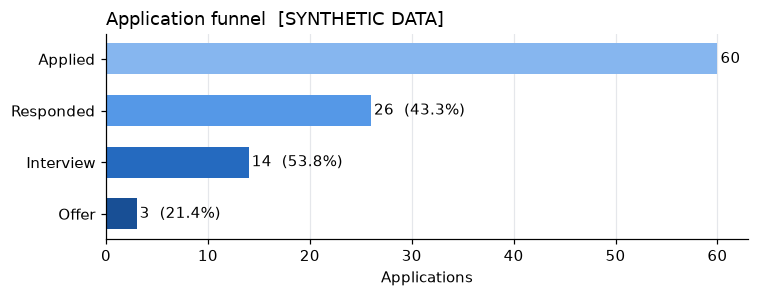

In [14]:
k = kpis(features)
funnel = pd.DataFrame({
    "stage": ["Applied", "Responded", "Interview", "Offer"],
    "applications": [k["applications"], k["responded"], k["reached_interview"], k["reached_offer"]],
})
funnel["% of previous stage"] = [None] + [
    rate(now, before) for before, now in zip(funnel["applications"], funnel["applications"][1:])]
funnel["% of all applications"] = [rate(value, k["applications"]) for value in funnel["applications"]]
display(funnel)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(funnel["stage"], funnel["applications"], color=FUNNEL_COLORS, height=0.6)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for y, (value, pct) in enumerate(zip(funnel["applications"], funnel["% of previous stage"])):
    ax.text(value + 0.3, y, f"{value}" + ("" if pd.isna(pct) else f"  ({pct}%)"), va="center")
ax.set_xlabel("Applications")
ax.set_title("Application funnel" + ("  [SYNTHETIC DATA]" if IS_SYNTHETIC else ""), loc="left")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "funnel.png")
plt.show()

## 8. Over time: is the search getting better?

Weekly volume shows effort; the reply rate shows results. **Careful:** recent
weeks haven't had time to get replies, so their rates look worse than they will
end up. That's why the reply-rate comparison only uses **mature** weeks
(applications at least 21 days old). Ignoring this is a classic analysis mistake.

,applications,reached_interview,responded,mature,response_rate_%
apply_week,,,,,
24 Aug,7,2,2,True,28.6
31 Aug,7,2,2,True,28.6
07 Sep,10,2,7,True,70.0
14 Sep,7,2,3,True,42.9
21 Sep,5,0,0,True,0.0
28 Sep,7,1,4,True,57.1
05 Oct,6,2,3,True,50.0
12 Oct,7,2,4,False,57.1
19 Oct,1,0,0,False,0.0


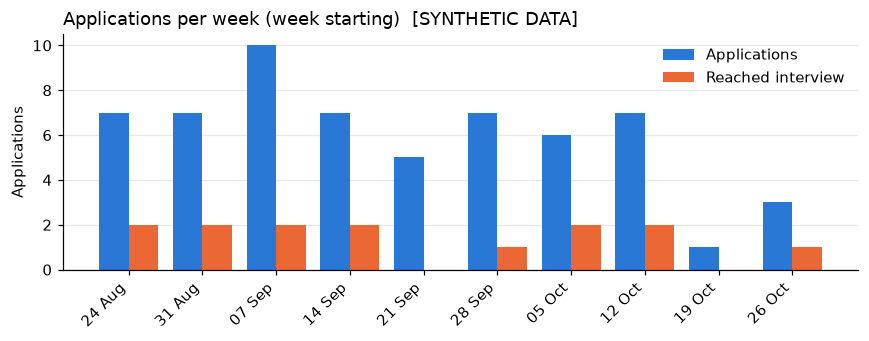

Reply rate, mature applications only: 45.1% (n=51); all applications: 43.3% (n=60)


In [15]:
weekly = (features.groupby("apply_week")
          .agg(applications=("company", "size"),
               reached_interview=("reached_interview", "sum"),
               responded=("responded", "sum"),
               mature=("mature", "all"))
          .asfreq("7D", fill_value=0))      # add weeks with no applications as zeros
weekly["mature"] = weekly["mature"].astype(bool)
weekly["response_rate_%"] = [rate(r, a) for r, a in zip(weekly["responded"], weekly["applications"])]
weekly.index = weekly.index.strftime("%d %b")
display(weekly)

fig, ax = plt.subplots(figsize=(8, 3.2))
x = range(len(weekly))
ax.bar([i - 0.2 for i in x], weekly["applications"], width=0.4, color=BLUE, label="Applications")
ax.bar([i + 0.2 for i in x], weekly["reached_interview"], width=0.4, color=ORANGE, label="Reached interview")
ax.set_xticks(list(x), weekly.index, rotation=45, ha="right")
ax.grid(axis="x", visible=False)
ax.set_ylabel("Applications")
ax.legend(frameon=False)
ax.set_title("Applications per week (week starting)" + ("  [SYNTHETIC DATA]" if IS_SYNTHETIC else ""), loc="left")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "weekly.png")
plt.show()

mature = features[features["mature"]]
print(f"Reply rate, mature applications only: {rate(mature['responded'].sum(), len(mature))}% "
      f"(n={len(mature)}); all applications: {k['response_rate_%']}% (n={k['applications']})")

## 9. Which channels lead to interviews?

A rate on its own can mislead with small numbers: **1 interview from 2
applications is "50%"** but says almost nothing. So for each channel we also show
a **95% confidence interval**: the range the true rate plausibly lies in, given
how little data there is. A wide interval means "we don't know yet".

We use the **Wilson interval**, which behaves well for small samples and for
rates near 0% or 100% (the simpler textbook formula doesn't).

,applications,responded,interviews,offers,response_rate_%,interview_rate_%,95% CI low,95% CI high
source,,,,,,,,
LinkedIn,19,7,4,1,36.8,21.1,8.5,43.3
Unknown,14,5,2,1,35.7,14.3,4.0,39.9
Referral,10,9,7,1,90.0,70.0,39.7,89.2
Company Website,10,4,1,0,40.0,10.0,1.8,40.4
Job Board,4,1,0,0,25.0,0.0,0.0,49.0
Recruiter,3,0,0,0,0.0,0.0,0.0,56.1


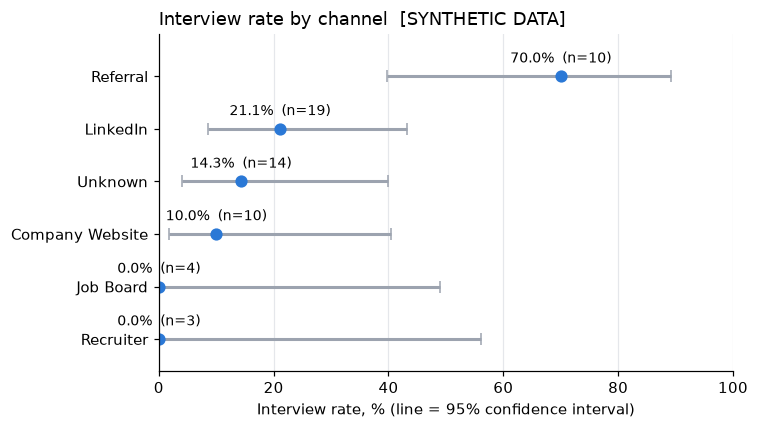

In [16]:
def wilson_interval(successes, n, confidence=0.95):
    """95% confidence interval for a proportion, in percent."""
    if n == 0:
        return (None, None)
    z = stats.norm.ppf(1 - (1 - confidence) / 2)        # 1.96 for 95%
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margin = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (round(100 * max(0, centre - margin), 1), round(100 * min(1, centre + margin), 1))

by_source = (features.groupby("source")
             .agg(applications=("company", "size"),
                  responded=("responded", "sum"),
                  interviews=("reached_interview", "sum"),
                  offers=("reached_offer", "sum"))
             .sort_values("applications", ascending=False))
by_source["response_rate_%"] = [rate(r, n) for r, n in zip(by_source["responded"], by_source["applications"])]
by_source["interview_rate_%"] = [rate(i, n) for i, n in zip(by_source["interviews"], by_source["applications"])]
intervals = [wilson_interval(i, n) for i, n in zip(by_source["interviews"], by_source["applications"])]
by_source["95% CI low"] = [low for low, _ in intervals]
by_source["95% CI high"] = [high for _, high in intervals]
display(by_source)

plot = by_source.sort_values("interview_rate_%")
fig, ax = plt.subplots(figsize=(7, 0.5 * len(plot) + 1))
ax.errorbar(plot["interview_rate_%"], plot.index,
            xerr=[plot["interview_rate_%"] - plot["95% CI low"], plot["95% CI high"] - plot["interview_rate_%"]],
            fmt="o", color=BLUE, ecolor=GREY, elinewidth=2, capsize=4, markersize=7)
for y, (value, n) in enumerate(zip(plot["interview_rate_%"], plot["applications"])):
    ax.annotate(f"{value}%  (n={n})", (value, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_ylim(-0.6, len(plot) - 0.2)   # room for the labels above the top point
ax.set_xlabel("Interview rate, % (line = 95% confidence interval)")
ax.grid(axis="y", visible=False)
ax.set_title("Interview rate by channel" + ("  [SYNTHETIC DATA]" if IS_SYNTHETIC else ""), loc="left")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "interview_rate_by_source.png")
plt.show()

### Is the difference real, or could it be chance? (hypothesis test)

**Question decided in advance:** do referrals lead to interviews more often than
all other channels combined? (Picking the comparison *after* seeing which channel
looks best would make a "significant" result much more likely by luck alone.)

- **Null hypothesis:** referrals and other channels have the same interview rate.
- **Test:** Fisher's exact test, which is exact for small samples (a chi-square
  test needs larger counts).
- **p-value:** if there were truly no difference, how often would we see a gap at
  least this big just by chance? Below 0.05 is the usual bar for "probably not chance".
- **With small samples a high p-value does not prove there is no difference**;
  it means there isn't enough data to tell.

In [17]:
GROUP = "Referral"
in_group = features["source"] == GROUP

if in_group.sum() == 0 or (~in_group).sum() == 0:
    print(f"Not enough data: need applications both from {GROUP} and from other channels.")
else:
    table = pd.crosstab(in_group.map({True: GROUP, False: "All other channels"}),
                        features["reached_interview"].map({True: "Interview", False: "No interview"}))
    table = table.reindex(columns=["Interview", "No interview"], fill_value=0)
    display(table)

    odds_ratio, p_value = stats.fisher_exact(table.to_numpy())
    rates = (table["Interview"] / table.sum(axis=1) * 100).round(1)
    print(f"Interview rate: {GROUP} {rates[GROUP]}% vs other channels {rates['All other channels']}%")
    print(f"Fisher's exact test p-value: {p_value:.3f}")
    if p_value < 0.05:
        print("-> A gap this large would be unlikely if there were no real difference "
              "(but check the sample size before acting on it).")
    else:
        print("-> Can't rule out chance: not enough evidence of a real difference yet.")

reached_interview,Interview,No interview
source,,
All other channels,7,43
Referral,7,3


Interview rate: Referral 70.0% vs other channels 14.0%
Fisher's exact test p-value: 0.001
-> A gap this large would be unlikely if there were no real difference (but check the sample size before acting on it).


## 10. Response time: how long should I wait before following up?

The median says how long a *typical* reply takes. The 90th percentile is more
useful for a decision: **90% of replies that came, came within this many days**,
so after that it's reasonable to follow up or move on.

Caveat: only applications that *got* a reply are included. Replies still on their
way would make the true wait a bit longer.

,days to first reply
count,25.0
mean,7.7
std,6.9
min,0.0
median,5.0
75th pct,10.0
90th pct,17.2
max,26.0


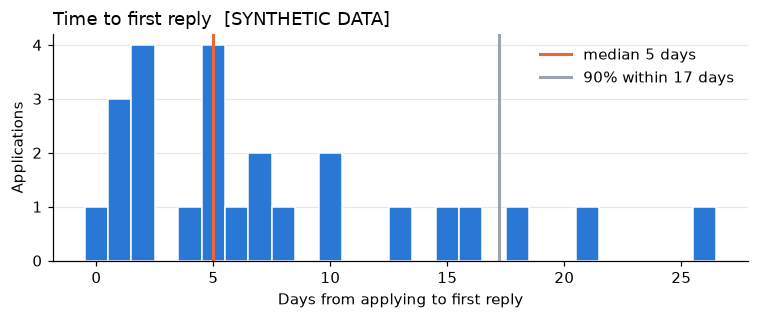

In [18]:
days = features["days_to_response"].dropna()

if days.empty:
    print("No replies with valid dates yet.")
else:
    summary = days.describe(percentiles=[0.5, 0.75, 0.9]).rename({"50%": "median", "75%": "75th pct", "90%": "90th pct"})
    display(summary.round(1).to_frame("days to first reply"))

    fig, ax = plt.subplots(figsize=(7, 3))
    # bin edges at -0.5, 0.5, 1.5, ... so each bar is centred on a whole number of days
    ax.hist(days, bins=[d - 0.5 for d in range(0, int(days.max()) + 2)], color=BLUE, edgecolor="white")
    ax.axvline(days.median(), color=ORANGE, linewidth=2, label=f"median {days.median():.0f} days")
    ax.axvline(days.quantile(0.9), color=GREY, linewidth=2, label=f"90% within {days.quantile(0.9):.0f} days")
    ax.set_xlabel("Days from applying to first reply")
    ax.set_ylabel("Applications")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False)
    ax.set_title("Time to first reply" + ("  [SYNTHETIC DATA]" if IS_SYNTHETIC else ""), loc="left")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "figures" / "response_time.png")
    plt.show()

## 11. The same analysis in SQL

Most analyst jobs use SQL every day. **DuckDB** runs SQL directly on pandas
DataFrames (and CSV files), so we can repeat the key calculations in SQL and
check that both methods agree.

The cleaned tables are available to SQL as `applications` and `status_events`,
linked by `job_id`, just like two tables in a company database.

In [19]:
con = duckdb.connect()
con.execute("SET TimeZone = 'UTC'")     # day boundaries in UTC, same as the app
con.register("applications", clean_apps)
con.register("status_events", clean_events)

def sql(query):
    return con.sql(query).df()

**Query 1: `GROUP BY`.** How many applications are at each current status?

In [20]:
sql("""
    SELECT current_status,
           COUNT(*)                                          AS applications,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_total
    FROM applications
    GROUP BY current_status
    ORDER BY applications DESC
""")

,current_status,applications,pct_of_total
0,Applied,34,56.7
1,Rejected,23,38.3
2,Offer,3,5.0


**Query 2: `JOIN` + CTE (the funnel).** A *CTE* (`WITH ... AS`) is a named
sub-query that keeps long SQL readable. We join each application to its status
history and use `BOOL_OR` ("was this true for any row?") to flag the stages it
ever reached.

It's a **`LEFT JOIN`**, not an inner `JOIN`: an application without any history
rows must still be counted. An inner join would silently drop it.

In [21]:
FUNNEL_SQL = """
    WITH job_stages AS (
        SELECT a.job_id,
               a.source,
               a.current_status,
               BOOL_OR(e.status IN ('Interview', 'Offer', 'Rejected'))
                   OR a.current_status <> 'Applied'                    AS responded,
               BOOL_OR(e.status IN ('Interview', 'Offer'))
                   OR a.current_status IN ('Interview', 'Offer')       AS reached_interview,
               BOOL_OR(e.status = 'Offer') OR a.current_status = 'Offer' AS reached_offer
        FROM applications AS a
        LEFT JOIN status_events AS e USING (job_id)
        GROUP BY a.job_id, a.source, a.current_status
    )
"""

funnel_sql = sql(FUNNEL_SQL + """
    SELECT COUNT(*)                                   AS applications,
           COUNT(*) FILTER (WHERE responded)          AS responded,
           COUNT(*) FILTER (WHERE reached_interview)  AS reached_interview,
           COUNT(*) FILTER (WHERE reached_offer)      AS reached_offer
    FROM job_stages
""")
funnel_sql

,applications,responded,reached_interview,reached_offer
0,60,26,14,3


**Query 3: conversion by channel.** The same CTE, grouped by source.

In [22]:
by_source_sql = sql(FUNNEL_SQL + """
    SELECT source,
           COUNT(*)                                                            AS applications,
           COUNT(*) FILTER (WHERE reached_interview)                           AS interviews,
           ROUND(100.0 * COUNT(*) FILTER (WHERE reached_interview) / COUNT(*), 1) AS interview_rate_pct
    FROM job_stages
    GROUP BY source
    ORDER BY applications DESC, source
""")
by_source_sql

,source,applications,interviews,interview_rate_pct
0,LinkedIn,19,4,21.1
1,Unknown,14,2,14.3
2,Company Website,10,1,10.0
3,Referral,10,7,70.0
4,Job Board,4,0,0.0
5,Recruiter,3,0,0.0


**Query 4: response time.** `MIN` finds each application's first reply, then
`DATE_DIFF` counts the days. `MEDIAN` and `QUANTILE_CONT` give the middle and
the 90th percentile.

In [23]:
response_sql = sql("""
    WITH first_reply AS (
        SELECT a.job_id,
               DATE_DIFF('day', a.date_applied, MIN(e.changed_at)) AS raw_days
        FROM applications AS a
        JOIN status_events AS e USING (job_id)
        WHERE e.status <> 'Applied'
        GROUP BY a.job_id, a.date_applied
    ),
    valid AS (
        SELECT CASE WHEN raw_days = -1 THEN 0 ELSE raw_days END AS days   -- timezone rule
        FROM first_reply
        WHERE raw_days >= -1                                              -- drop impossible dates
    )
    SELECT COUNT(*)                         AS replies,
           MEDIAN(days)                     AS median_days,
           ROUND(AVG(days), 1)              AS average_days,
           QUANTILE_CONT(days, 0.9)         AS p90_days
    FROM valid
""")
response_sql

,replies,median_days,average_days,p90_days
0,25,5.0,7.7,17.2


**Query 5: window function (running total).** Window functions (`... OVER (...)`)
calculate across rows without collapsing them, which `GROUP BY` can't do. Here:
applications per week plus the running total so far, a very common interview question.

In [24]:
sql("""
    WITH weekly AS (                                     -- step 1: one row per week
        SELECT DATE_TRUNC('week', date_applied)::DATE AS week_starting,
               COUNT(*)                               AS applications
        FROM applications
        GROUP BY week_starting
    )
    SELECT week_starting,                                -- step 2: window over those rows
           applications,
           SUM(applications) OVER (ORDER BY week_starting) AS running_total
    FROM weekly
    ORDER BY week_starting
""")

,week_starting,applications,running_total
0,2026-08-24,7,7.0
1,2026-08-31,7,14.0
2,2026-09-07,10,24.0
3,2026-09-14,7,31.0
4,2026-09-21,5,36.0
5,2026-09-28,7,43.0
6,2026-10-05,6,49.0
7,2026-10-12,7,56.0
8,2026-10-19,1,57.0
9,2026-10-26,3,60.0


**Do SQL and pandas agree?** If two independent implementations give the same
numbers, we can be much more confident both are right.

In [25]:
checks = {
    "applications": (int(funnel_sql.at[0, "applications"]), k["applications"]),
    "responded": (int(funnel_sql.at[0, "responded"]), k["responded"]),
    "reached_interview": (int(funnel_sql.at[0, "reached_interview"]), k["reached_interview"]),
    "reached_offer": (int(funnel_sql.at[0, "reached_offer"]), k["reached_offer"]),
    "replies with valid dates": (int(response_sql.at[0, "replies"]), k["responses_with_valid_dates"]),
    "median days to reply": (float(response_sql.at[0, "median_days"]), k["median_days_to_response"]),
    "interviews by source": (by_source_sql.set_index("source")["interviews"].astype(int).sort_index().to_dict(),
                             by_source["interviews"].astype(int).sort_index().to_dict()),
}
comparison = pd.DataFrame(checks, index=["SQL", "pandas"]).T
comparison["match"] = [sql_value == pandas_value for sql_value, pandas_value in checks.values()]
display(comparison)
assert comparison["match"].all(), "SQL and pandas disagree: investigate before trusting either!"
print("SQL and pandas agree on every check.")

,SQL,pandas,match
applications,60,60,True
responded,26,26,True
reached_interview,14,14,True
reached_offer,3,3,True
replies with valid dates,25,25,True
median days to reply,5.0,5.0,True
interviews by source,"{'Company Website': 1, 'Job Board': 0, 'Linked...","{'Company Website': 1, 'Job Board': 0, 'Linked...",True


SQL and pandas agree on every check.


## 12. Summary and next steps

The table below collects the key numbers. Write the interpretation in
[`insights.md`](insights.md): what you found, what you'll change, and the
limitations.

**Only write findings from a REAL export.** With synthetic data, this notebook is
practice: the patterns were programmed into the generator.

In [26]:
summary = {
    "data": "SYNTHETIC (practice only)" if IS_SYNTHETIC else "REAL export",
    "as_of": AS_OF.strftime("%Y-%m-%d"),
    "kpis_app_raw": kpis(raw_features),
    "kpis_cleaned": kpis(features),
    "cleaning_log": dict(zip(cleaning_log["cleaning step"], cleaning_log["rows changed"].astype(int))),
}

(OUTPUT_DIR / "kpis.json").write_text(json.dumps(summary, indent=2))
clean_apps.to_csv(OUTPUT_DIR / "clean_applications.csv", index=False)
features.reset_index().to_csv(OUTPUT_DIR / "application_features.csv", index=False)

print("Saved: outputs/kpis.json, outputs/clean_applications.csv, outputs/application_features.csv, outputs/figures/*.png")
print()
print("DATA SOURCE:", summary["data"])
pd.Series(summary["kpis_cleaned"]).to_frame("value")

Saved: outputs/kpis.json, outputs/clean_applications.csv, outputs/application_features.csv, outputs/figures/*.png

DATA SOURCE: SYNTHETIC (practice only)


,value
applications,60.0
responded,26.0
reached_interview,14.0
reached_offer,3.0
rejected,23.0
awaiting_response,34.0
stale,28.0
response_rate_%,43.3
interview_rate_%,23.3
offer_rate_%,5.0
